In [1]:
import numpy as np
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

# 1. Instantiate BallStick (Ball + Stick compartments)
microtorch_model = ModelMaker("BallStick")
ball, stick = microtorch_model.compartments

# 2. Wrap each compartment individually in MicrotorchTissueModel
ball_model = MicrotorchTissueModel(
    ball,
    parameters={"D": 1.8},
)

stick_model = MicrotorchTissueModel(
    stick,
    parameters={"Dpar": 1.8, "theta": np.pi / 4, "phi": np.pi / 3},
)

# Hold D and Dpar fixed (do not optimize or fit)
ball_model["D"].optimize = True
ball_model["D"].fit_flag = True
ball_model["D"].fit_bounds = (0.1, 3.0)

stick_model["Dpar"].optimize = False
stick_model["Dpar"].fit_flag = False
stick_model["Dpar"].fit_bounds = (0.5, 3.0)

# Hold stick directions (theta, phi) fixed
stick_model["theta"].fit_flag = True
stick_model["theta"].optimize = True

stick_model["phi"].fit_flag = True
stick_model["phi"].optimize = True

# 3. Wrap each compartment with T2 relaxation
ball_relax = RelaxationTissueModel(ball_model, t2=120e-3 * unit("s"))
stick_relax = RelaxationTissueModel(stick_model, t2=75e-3 * unit("s"))

# Set realistic T2 fit bounds (prevents exp(-TE/T2) overflow near 0 and multi-start wild guesses)
ball_relax["T2"].optimize = True
ball_relax["T2"].fit_flag = True
ball_relax["T2"].scale = 1
ball_relax["T2"].fit_bounds = (0.040, 0.500)   # Extra-axonal / free water: 40 ms to 500 ms

stick_relax["T2"].optimize = True
stick_relax["T2"].fit_flag = True
stick_relax["T2"].scale = 1
stick_relax["T2"].fit_bounds = (0.020, 0.200)  # Intra-axonal stick: 20 ms to 200 ms

# 4. Combine into MultiTissueModel
vfs = [0.4]
vfs.append(1.0 - sum(vfs))  # [0.4, 0.6]

model = MultiTissueModel(
    [ball_relax, stick_relax],
    volume_fractions=vfs,
)

# Keep volume fractions away from exact 0/1 boundaries during random multi-start
model["vf_0"].fit_flag = True
model["vf_0"].fit_bounds = (0.01, 0.99)

model["vf_1"].optimize = False
model["vf_1"].fit_flag = False
model["vf_1"].fit_bounds = (0.01, 0.99)

# Realistic S0 bounds around normalized baseline 1.0
model["S0"].optimize = True
model["S0"].fit_flag = True
model["S0"].fit_bounds = (0.5, 1.5)

print(model)

No YAML configuration found for BallStick model.
Falling back to parsing model name for compartments: ['Ball', 'Stick'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  BallStick
########### Compartments: ['Ball', 'Stick']
########### Parameter names: [['D'], ['Dpar', 'theta', 'phi']]
########### Parameter ranges: [[[0.001, 3]], [[0.001, 3], [-1.5707963267948966, 1.5707963267948966], [0, 3.141592653589793]]]
-----------
Tissue model with 9 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
-------------------  --------  -------  ----------  -----  -----------------------------------------
model_0_model_D      1.8             1  True        True   (0.1, 3.0)
model_0_T2           0.12            1  True        True   (0.04, 0.5)
model_1_model_Dpar   1.8             1  False       False  (0.5, 3.0)
model_1_model_theta  0.785398        1  True        True   (-1.5707963267948966, 1.5707963267948966)
model_

In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling.shell_electrostatic import sample_shells_electrostatic

n_dirs = 6   # directions per shell

# Five (b, delta, Delta, TE) conditions, each measured with two direction sets
b     = [200, 200, 600, 1200, 2000, 200, 200, 600, 1200, 2000]             # s/mm^2
delta = [0.011, 0.011, 0.015, 0.018, 0.021,0.011, 0.011, 0.015, 0.018, 0.021]       # s
Delta = [0.021, 0.021, 0.025, 0.028, 0.031,0.021, 0.021, 0.025, 0.028, 0.031]       # s
TE    = [0.040, 0.085, 0.050, 0.065, 0.075,0.040, 0.085, 0.050, 0.065, 0.075]     # s

# Uniformly distributed gradient directions for all shells
directions = np.vstack(sample_shells_electrostatic([n_dirs] * len(b)))

scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=np.repeat(b, n_dirs),
    b_vectors=directions,
    pulse_durations=np.repeat(delta, n_dirs),
    pulse_intervals=np.repeat(Delta, n_dirs),
    echo_times=np.repeat(TE, n_dirs),
)

# One free value per shell, shared by its 12 directions
for name in ("EchoTime", "DiffusionPulseDuration",
             "DiffusionPulseInterval", "DiffusionPulseMagnitude"):
    scheme[name].set_repetition_period(n_dirs)

print(scheme)

Acquisition scheme with 60 measurements and 6 scalar parameters. 
total number of optimized parameters is 40:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.2)    DiffusionPulseInterval [s] in (0.01, 0.2)    EchoTime [s] in (0.01, 0.2)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                        0.036492                                   0.395526                                      2.11583                                         0.011                                        0.021                          0.04
                                        0.036492                                  -1.08493                        

In [3]:
from microtool.optimize.loss_functions import CrlbLoss, fisher_information_rice, rice_loss, compute_loss

jacobian = model.scaled_jacobian(scheme)
signal = model(scheme)

FIM = fisher_information_rice(jacobian, signal, noise_var=0.02)
CRLB = rice_loss.crlb(jac=jacobian, signal=signal, noise_var=0.02)

objective_loss = compute_loss(scheme, model, noise_var=0.02, loss=rice_loss)

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [4]:
import copy
import numpy as np
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme
from microtool.optimize.loss_functions import compute_loss, default_loss, rice_loss_2

n_runs = 1
noise_variance = 0.02
loss_function = default_loss  # or whichever loss function you intend to evaluate

optimization_history = []

for run_idx in range(n_runs):
    print(f"--- Running optimization {run_idx + 1}/{n_runs} ---")
    
    # Instantiate method per run to ensure clean state
    method = methods.SOMA()
    
    # Pass a deep copy of initial_scheme so in-place edits don't contaminate subsequent runs
    scheme_run, opt_info = optimize_scheme(
        copy.deepcopy(scheme),
        model,
        noise_variance=noise_variance,
        method=method,
        loss = rice_loss_2
    )
    
    # Compute the final loss value for this optimized scheme
    current_loss = compute_loss(
        scheme_run,
        model,
        noise_variance,
        loss_function,
    )
    
    optimization_history.append({
        "run": run_idx + 1,
        "scheme": scheme_run,
        "loss": float(current_loss),
        "info": opt_info,
    })
    
    print(f"Run {run_idx + 1} completed with loss: {current_loss:.6e}")

# Find the run with the minimum loss
best_result = min(optimization_history, key=lambda res: res["loss"])
optimal_scheme_SOMA = best_result["scheme"]

print("\n=== Optimization Summary ===")
for res in optimization_history:
    print(f"Run {res['run']}: Loss = {res['loss']:.6e}")

print(f"\nBest Run: #{best_result['run']} with Lowest Loss = {best_result['loss']:.6e}")

--- Running optimization 1/1 ---
[SOMA] Starting Optimization
  Dimension (Nx)     : 40
  Population Size    : 50
  Max Migrations     : 500
  Max Fevals         : 4000000
  Jumps per movement : 28
[Init] hit-and-run from x0 | Nx=40, target=50, burn_in=2000, thin=100, n_active=None
[Init]   2/50 | step=2100 | segment (rel)=1.287e-01 | dist from x0 (rel)=7.864e-01
[Init]   3/50 | step=2200 | segment (rel)=1.625e-02 | dist from x0 (rel)=7.966e-01
[Init]   4/50 | step=2300 | segment (rel)=7.918e-02 | dist from x0 (rel)=7.887e-01
[Init]   5/50 | step=2400 | segment (rel)=1.633e-02 | dist from x0 (rel)=8.193e-01
[Init]   6/50 | step=2500 | segment (rel)=1.496e-02 | dist from x0 (rel)=7.914e-01
[Init]   7/50 | step=2600 | segment (rel)=1.616e-01 | dist from x0 (rel)=8.165e-01
[Init]   8/50 | step=2700 | segment (rel)=5.517e-02 | dist from x0 (rel)=8.280e-01
[Init]   9/50 | step=2800 | segment (rel)=5.918e-02 | dist from x0 (rel)=8.361e-01
[Init]  10/50 | step=2900 | segment (rel)=1.795e-02 |

In [5]:

print(optimal_scheme_SOMA)
print(optimal_scheme_SOMA.b_values)


Acquisition scheme with 60 measurements and 6 scalar parameters. 
total number of optimized parameters is 40:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.2)    DiffusionPulseInterval [s] in (0.01, 0.2)    EchoTime [s] in (0.01, 0.2)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                      0.0707179                                    0.395526                                      2.11583                                     0.0158692                                    0.0385542                      0.0584239
                                      0.0707179                                   -1.08493                       

In [6]:
from pathlib import Path
import pickle
from microtool.monte_carlo.IO import make_expirement_directories

# Pass parent directory as cwd / "Ball_T2", experiment as "Shell_3"
plotdir, modeldir, simdir, schemedir = make_expirement_directories(
    Path.cwd() / "Ball_Stick_T2", "First_Test_Small_Shell"
)
print(schemedir)

# Save schemes and model
with open(schemedir / "initial_scheme.pkl", "wb") as f:
  pickle.dump(scheme, f)

with open(schemedir / "optimal_scheme.pkl", "wb") as f:
  pickle.dump(optimal_scheme_SOMA, f)

with open(modeldir / "model.pkl", "wb") as f:
  pickle.dump(ball_model, f)

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_Stick_T2/First_Test_Small_Shell/schemes


In [7]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats
import matplotlib.pyplot as plt

noise_distribution = stats.norm(0, scale=0.02)



# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    scheme,
    model,
    noise_distribution,
    n_sim=1000,
    fit_options={"method": "SLSQP"},
    random_state=43
)
simulation.run()
initial = simulation.result
simulation.save(simdir / "initial.pkl")


# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme_SOMA)
simulation.run()
optimal = simulation.result
simulation.save(simdir / "optimal.pkl")

Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [10:44<00:00,  1.55it/s]


/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/monte_carlo/IO.py:38: UserWarning: There is already a folder with the name of the experiment. No new folders have been created.
  warnings.warn("There is already a folder with the name of the experiment. No new folders have been created.")


Valid fits: initial=1000, optimal=1000

Initial scheme
                         bias      std     RMSE  scaled bias  scaled std  \
model_0_T2           0.08532  0.15093  0.17337      0.71101     1.25771   
model_1_T2           0.00371  0.04313  0.04329      0.04953     0.57511   
model_0_model_D     -0.13122  0.66996  0.68269     -0.07290     0.37220   
model_1_model_theta -0.08149  0.27169  0.28365     -0.05188     0.17297   
model_1_model_phi   -0.02255  0.61186  0.61228     -0.00718     0.19476   
vf_0                 0.07124  0.19118  0.20402      0.17811     0.47794   
S0                   0.05805  0.11928  0.13266      0.05805     0.11928   

                     scaled RMSE  
model_0_T2               1.44477  
model_1_T2               0.57724  
model_0_model_D          0.37927  
model_1_model_theta      0.18058  
model_1_model_phi        0.19489  
vf_0                     0.51005  
S0                       0.13266   
TOTAL scaled RMSE: 0.64507

Optimal scheme
                   

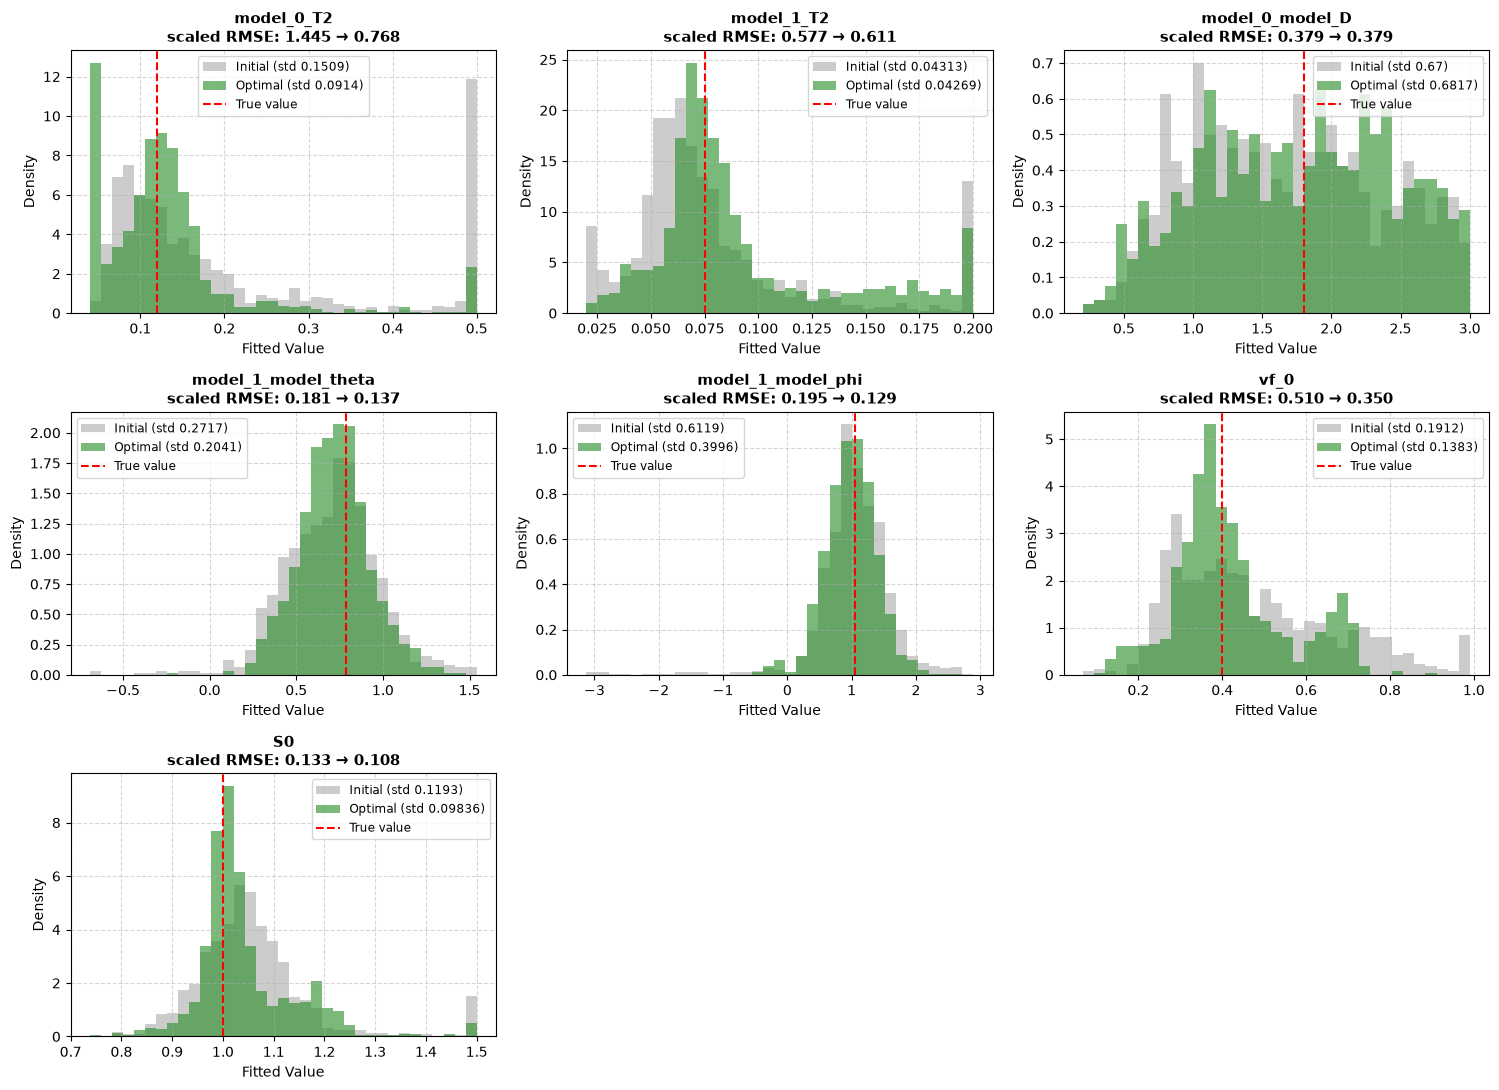

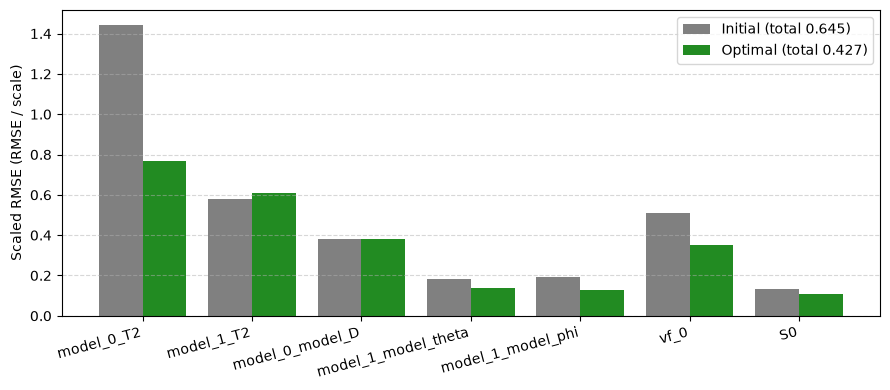

In [8]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from microtool.monte_carlo.IO import make_expirement_directories

# ------------------------------------------------------------------ paths & loading
base_dir = Path.cwd() / "Ball_Stick_T2"
experiment_name = "First_Test_Small_Shell"

plotdir, modeldir, simdir, schemedir = make_expirement_directories(
    base_dir, experiment_name
)

initial_path = simdir / "initial.pkl"
optimal_path = simdir / "optimal.pkl"  # Note: change your save script from "initial.pkl" to "optimal.pkl"

with open(initial_path, "rb") as f:
    initial = pickle.load(f)

with open(optimal_path, "rb") as f:
    optimal = pickle.load(f)

# ------------------------------------------------------------------ data
df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

# Ground truth used for the BallStick + T2 simulation (matching fitted columns)
true_values = {
    "model_0_T2":          0.120,
    "model_1_T2":          0.075,
    "model_0_model_D":     1.8,      # <-- Set to your simulation's ball diffusivity
    "model_1_model_theta": np.pi / 4,   # Match stick_model["theta"]
    "model_1_model_phi":   np.pi / 3,   # Match stick_model["phi"]
    "vf_0":                0.4,
    "vf_1":                0.6,
    "S0":                  1.0,
}

# Unwrap antipodal stick symmetry (theta in [-pi/2, pi/2], phi in [0, pi])
true_th = true_values["model_1_model_theta"]
true_ph = true_values["model_1_model_phi"]
u_true = np.array([
    np.cos(true_th) * np.cos(true_ph),
    np.cos(true_th) * np.sin(true_ph),
    np.sin(true_th),
])

def align_stick_angles(df):
    if {"model_1_model_theta", "model_1_model_phi"}.issubset(df.columns):
        th = df["model_1_model_theta"].to_numpy()
        ph = df["model_1_model_phi"].to_numpy()
        ux = np.cos(th) * np.cos(ph)
        uy = np.cos(th) * np.sin(ph)
        uz = np.sin(th)
        vecs = np.column_stack([ux, uy, uz])

        # Flip vectors whose dot product with u_true is negative
        flip = (vecs @ u_true) < 0
        vecs[flip] *= -1.0

        df["model_1_model_theta"] = np.arcsin(np.clip(vecs[:, 2], -1.0, 1.0))
        df["model_1_model_phi"] = np.arctan2(vecs[:, 1], vecs[:, 0])
    return df

df_init = align_stick_angles(df_init)
df_opt = align_stick_angles(df_opt)

# Scales for relative RMSE
scales = {
    "model_0_T2":          0.120,
    "model_1_T2":          0.075,
    "model_0_model_D":     1.8,      # <-- Match true_values["model_0_model_D"]
    "model_1_model_theta": np.pi / 2.0,
    "model_1_model_phi":   np.pi,
    "vf_0":                0.4,
    "vf_1":                0.6,
    "S0":                  1.0,
}
# Select only fitted columns present in both DataFrames
common_cols = [c for c in true_values if c in df_init.columns and c in df_opt.columns]
extra = [
    c for c in df_opt.columns
    if c in df_init.columns and c not in true_values
]
if extra:
    print(f"Skipping fixed/untracked columns: {extra}")

df_init = df_init[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
df_opt = df_opt[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Valid fits: initial={len(df_init)}, optimal={len(df_opt)}")

# ------------------------------------------------------------------ RMSE
def rmse_table(df):
    rows = {}
    for col in common_cols:
        err = df[col].to_numpy() - true_values[col]
        rmse = np.sqrt(np.mean(err ** 2))
        s = abs(scales[col])
        rows[col] = {
            "bias": err.mean(),
            "std": err.std(),
            "RMSE": rmse,
            "scaled bias": err.mean() / s,
            "scaled std": err.std() / s,
            "scaled RMSE": rmse / s,
        }
    tab = pd.DataFrame(rows).T
    total = np.sqrt(np.mean(tab["scaled RMSE"] ** 2))
    return tab, total

tab_init, total_init = rmse_table(df_init)
tab_opt, total_opt = rmse_table(df_opt)

print("\nInitial scheme\n", tab_init.round(5), f"\nTOTAL scaled RMSE: {total_init:.5f}")
print("\nOptimal scheme\n", tab_opt.round(5), f"\nTOTAL scaled RMSE: {total_opt:.5f}")
print(f"\nImprovement of total scaled RMSE: {100 * (1 - total_opt / total_init):.1f}%")

# ------------------------------------------------------------------ 3x3 histograms
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 11))
axes_flat = axes.ravel()

for i, col in enumerate(common_cols):
    ax = axes_flat[i]

    both = np.concatenate([df_init[col].to_numpy(), df_opt[col].to_numpy()])
    bins = np.linspace(both.min(), both.max(), 36)

    ax.hist(
        df_init[col],
        bins=bins,
        density=True,
        alpha=0.4,
        color="gray",
        label=f"Initial (std {tab_init.loc[col, 'std']:.4g})",
    )
    ax.hist(
        df_opt[col],
        bins=bins,
        density=True,
        alpha=0.6,
        color="forestgreen",
        label=f"Optimal (std {tab_opt.loc[col, 'std']:.4g})",
    )
    ax.axvline(true_values[col], color="red", linestyle="--", linewidth=1.5, label="True value")
    ax.set_title(
        f"{col}\nscaled RMSE: {tab_init.loc[col, 'scaled RMSE']:.3f} → {tab_opt.loc[col, 'scaled RMSE']:.3f}",
        fontsize=11,
        fontweight="bold",
    )
    ax.set_xlabel("Fitted Value")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.5)

# Hide unused subplots in the 3x3 grid (e.g., slots 7 and 8 when 7 parameters are plotted)
for j in range(len(common_cols), len(axes_flat)):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.savefig(plotdir / "histograms.png", dpi=300)
plt.show()

# ------------------------------------------------------------------ bar plot
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(common_cols))
ax.bar(
    x - 0.2,
    tab_init["scaled RMSE"],
    0.4,
    color="gray",
    label=f"Initial (total {total_init:.3f})",
)
ax.bar(
    x + 0.2,
    tab_opt["scaled RMSE"],
    0.4,
    color="forestgreen",
    label=f"Optimal (total {total_opt:.3f})",
)
ax.set_xticks(x)
ax.set_xticklabels(common_cols, rotation=15, ha="right")
ax.set_ylabel("Scaled RMSE (RMSE / scale)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()

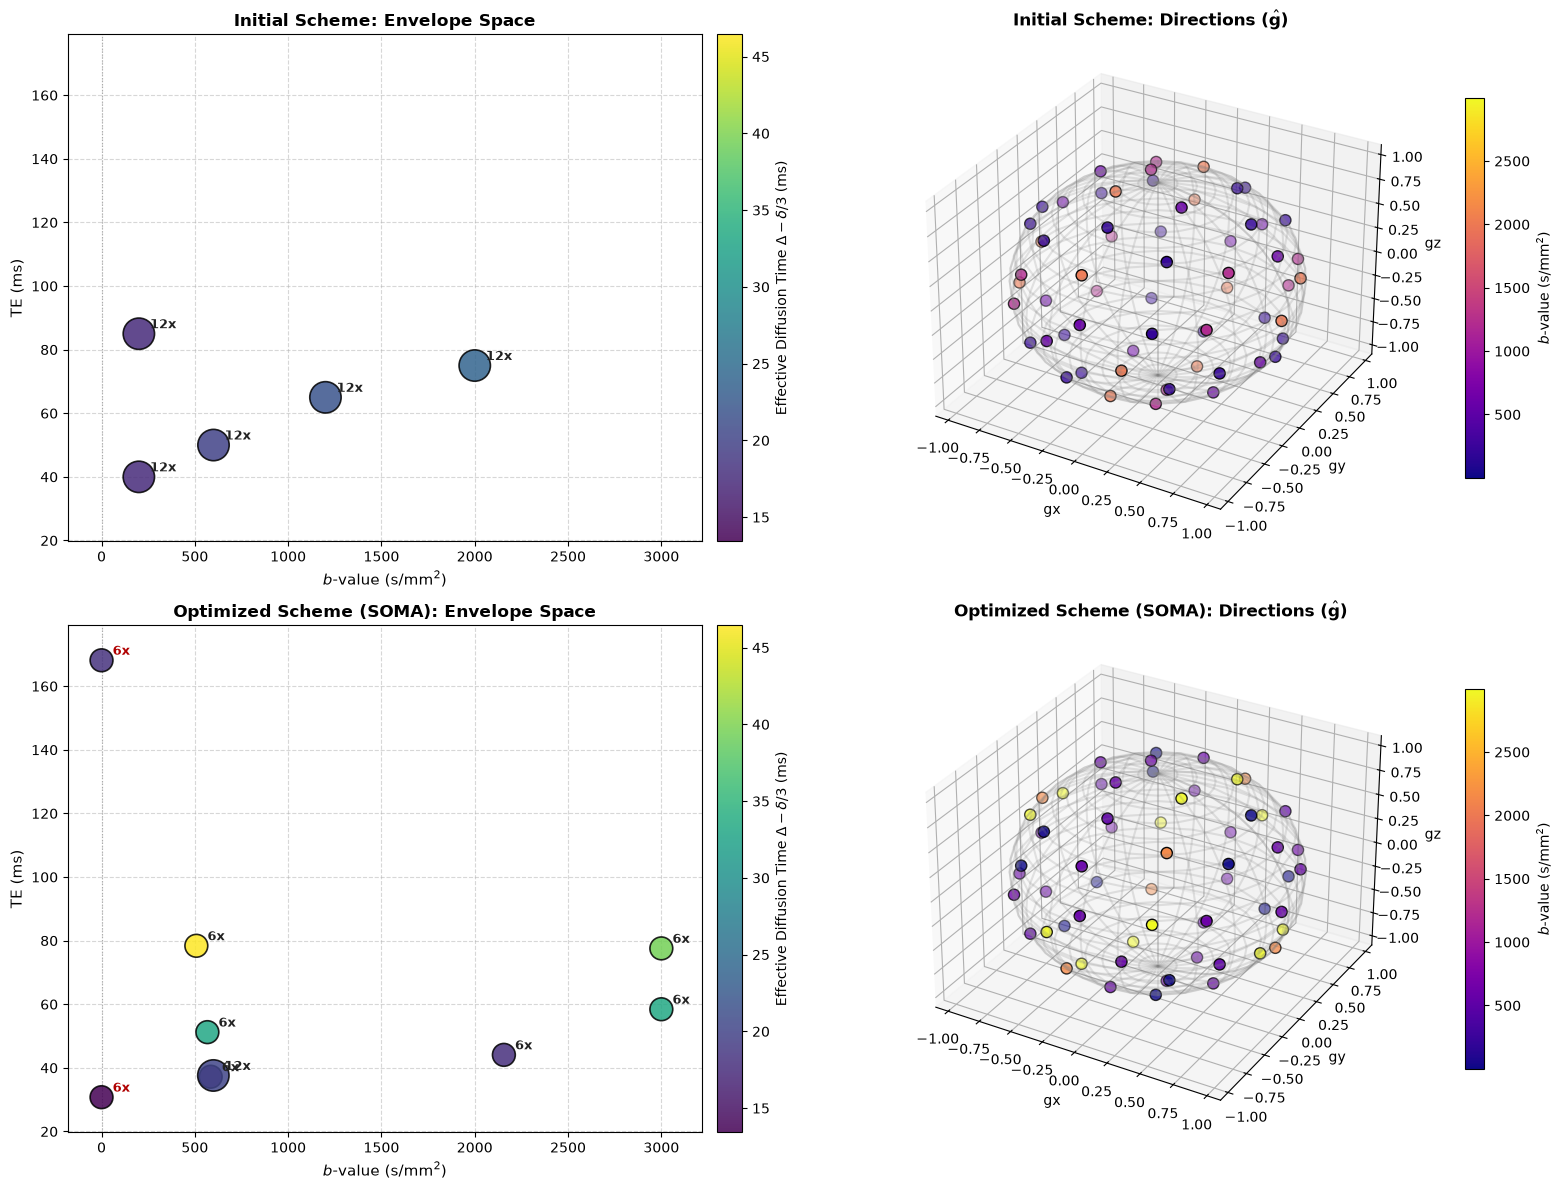


=== Optimized Shells (Merged Tolerance: Δb ≤ 50 s/mm², ΔTE ≤ 5 ms) ===
b ≈   0.0 s/mm² | Directions:  6 | TE: [30.8, 30.8] ms | Δ_eff: [13.4, 13.4] ms
b ≈   0.0 s/mm² | Directions:  6 | TE: [168.1, 168.1] ms | Δ_eff: [18.1, 18.1] ms
b ≈ 508.1 s/mm² | Directions:  6 | TE: [78.4, 78.4] ms | Δ_eff: [46.5, 46.5] ms
b ≈ 567.2 s/mm² | Directions:  6 | TE: [51.2, 51.2] ms | Δ_eff: [33.1, 33.1] ms
b ≈ 584.9 s/mm² | Directions:  6 | TE: [37.2, 37.2] ms | Δ_eff: [15.6, 15.6] ms
b ≈ 599.2 s/mm² | Directions: 12 | TE: [37.5, 37.7] ms | Δ_eff: [20.2, 20.3] ms
b ≈ 2156.2 s/mm² | Directions:  6 | TE: [44.1, 44.1] ms | Δ_eff: [17.9, 17.9] ms
b ≈ 3000.0 s/mm² | Directions:  6 | TE: [58.4, 58.4] ms | Δ_eff: [33.3, 33.3] ms
b ≈ 3000.0 s/mm² | Directions:  6 | TE: [77.6, 77.6] ms | Δ_eff: [39.4, 39.4] ms
Found only 0 directions in window; widen b_window or te_window.


In [9]:
from pathlib import Path
import pickle
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


def extract_scheme_parameters(scheme):
    """Extracts b-values, echo times, effective diffusion times (Delta - delta/3),
    and gradient vectors directly from DiffusionAcquisitionScheme properties.
    Ensures timings are in milliseconds and b-values in s/mm².
    """
    # 1. b-values (s/mm²)
    b_vals = np.asarray(scheme.b_values, dtype=float).flatten()
    if np.nanmax(b_vals) > 50000:
        b_vals = b_vals / 1e6

    # 2. Echo times (seconds -> ms)
    te_vals = np.asarray(scheme.echo_times, dtype=float).flatten()
    if np.nanmax(te_vals) < 1.0 and np.any(te_vals > 0):
        te_vals = te_vals * 1e3

    # 3. Pulse interval (Delta) and pulse duration (delta) (seconds -> ms)
    big_delta = np.asarray(scheme.pulse_intervals, dtype=float).flatten()
    small_delta = np.asarray(scheme.pulse_durations, dtype=float).flatten()

    if np.nanmax(big_delta) < 1.0 and np.any(big_delta > 0):
        big_delta = big_delta * 1e3

    if np.nanmax(small_delta) < 1.0 and np.any(small_delta > 0):
        small_delta = small_delta * 1e3

    # Effective diffusion time: Delta - delta / 3 (ms)
    delta_eff = big_delta - (small_delta / 3.0)

    # 4. Directions and unit vectors
    b_vecs = np.asarray(scheme.b_vectors, dtype=float)
    norms = np.linalg.norm(b_vecs, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    unit_dirs = b_vecs / norms

    return b_vals, te_vals, delta_eff, b_vecs, unit_dirs


def aggregate_envelope_points(
    b, te, delta, b_tol=50.0, te_tol=5.0, delta_tol=5.0, base_size=70, scale_factor=40
):
    """Groups points using tolerance bins so nearby converged shells cluster together:
    - b_tol:      b-values clustered within this window (e.g., 50 s/mm²)
    - te_tol:     TE values clustered within this window (e.g., 5.0 ms)
    - delta_tol:  Delta_eff values clustered within this window (e.g., 5.0 ms)
    """
    b_bins = np.round(b / b_tol) * b_tol
    te_bins = np.round(te / te_tol) * te_tol
    delta_bins = np.round(delta / delta_tol) * delta_tol

    coords = np.column_stack([b_bins, te_bins, delta_bins])
    unique_coords, inverse_indices, counts = np.unique(
        coords, axis=0, return_inverse=True, return_counts=True
    )

    n_clusters = len(unique_coords)
    agg_b = np.zeros(n_clusters)
    agg_te = np.zeros(n_clusters)
    agg_delta = np.zeros(n_clusters)

    for i in range(n_clusters):
        mask = inverse_indices == i
        agg_b[i] = np.mean(b[mask])
        agg_te[i] = np.mean(te[mask])
        agg_delta[i] = np.mean(delta[mask])

    agg_sizes = base_size + (counts - 1) * scale_factor

    return agg_b, agg_te, agg_delta, agg_sizes, counts


def plot_combined_shell_uniformity(
    b_vals, te_vals, unit_dirs, b_target=440.0, b_window=40.0, te_target=33.0, te_window=5.0
):
    """Combines nearby converged shells onto one unit sphere, color-coding each
    sub-shell and evaluating overall angular uniformity across all directions.
    """
    mask = (np.abs(b_vals - b_target) <= b_window) & (
        np.abs(te_vals - te_target) <= te_window
    )
    dirs = unit_dirs[mask]
    b_sub = b_vals[mask]
    te_sub = te_vals[mask]

    n_dir = len(dirs)
    if n_dir < 2:
        print(f"Found only {n_dir} directions in window; widen b_window or te_window.")
        return

    # Group into the constituent sub-shells (e.g., 430, 440, 450)
    shell_keys = np.column_stack([np.round(b_sub, -1), np.round(te_sub, 1)])
    unique_shells, shell_ids = np.unique(shell_keys, axis=0, return_inverse=True)

    # Compute pairwise antipodal angles across the combined directions
    dot_mat = np.clip(np.abs(dirs @ dirs.T), 0.0, 1.0)
    np.fill_diagonal(dot_mat, 0.0)
    angle_mat_deg = np.degrees(np.arccos(dot_mat))
    np.fill_diagonal(angle_mat_deg, np.nan)

    min_angle = np.nanmin(angle_mat_deg)
    nearest_neighbor_angles = np.nanmin(angle_mat_deg, axis=1)
    mean_nn_angle = np.mean(nearest_neighbor_angles)

    # Plot unit sphere
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection="3d")

    u = np.linspace(0, 2 * np.pi, 30)
    v = np.linspace(0, np.pi, 20)
    ax.plot_wireframe(
        np.outer(np.cos(u), np.sin(v)),
        np.outer(np.sin(u), np.sin(v)),
        np.outer(np.ones_like(u), np.cos(v)),
        color="lightgray",
        linewidth=0.5,
        alpha=0.4,
    )

    colors = plt.cm.tab10(np.linspace(0, 0.6, len(unique_shells)))

    for s_idx, (b_s, te_s) in enumerate(unique_shells):
        s_mask = shell_ids == s_idx
        d_s = dirs[s_mask]
        c = colors[s_idx]
        label = f"b≈{int(b_s)} s/mm², TE={te_s:.1f} ms ({np.sum(s_mask)} dirs)"

        # +g (solid) and -g antipodal (open)
        ax.scatter(
            d_s[:, 0],
            d_s[:, 1],
            d_s[:, 2],
            color=c,
            s=95,
            edgecolors="k",
            lw=1.0,
            label=label,
        )
        ax.scatter(
            -d_s[:, 0],
            -d_s[:, 1],
            -d_s[:, 2],
            facecolors="none",
            edgecolors=c,
            s=95,
            lw=1.3,
        )

        for g in d_s:
            ax.plot(
                [-g[0], g[0]],
                [-g[1], g[1]],
                [-g[2], g[2]],
                color=c,
                alpha=0.35,
                lw=1.0,
            )

    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])
    ax.set_zlim([-1.1, 1.1])
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlabel("gx")
    ax.set_ylabel("gy")
    ax.set_zlabel("gz")
    ax.set_title(
        f"Combined Shell Uniformity ({n_dir} directions)\n"
        f"Min pairwise angle: {min_angle:.1f}° | Mean nearest-neighbor angle: {mean_nn_angle:.1f}°",
        fontsize=11,
        fontweight="bold",
    )
    ax.legend(loc="upper right", fontsize=8.5)
    plt.tight_layout()
    plt.show()


# -------------------------------------------------------------
# 1. Load Schemes
# -------------------------------------------------------------
schemedir = Path(
    "/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_Stick_T2/First_Test_Small_Shell/schemes"
)

if not (schemedir / "optimal_scheme.pkl").exists():
    matches = list(Path.cwd().rglob("optimal_scheme.pkl"))
    if matches:
        schemedir = matches[0].parent

init_path = schemedir / "initial_scheme.pkl"
opt_path = schemedir / "optimal_scheme.pkl"

if init_path.stat().st_size == 0 or opt_path.stat().st_size == 0:
    raise RuntimeError(
        f"One or more scheme pickle files are empty (0 bytes) in {schemedir}."
    )

with open(init_path, "rb") as f:
    initial_scheme = pickle.load(f)

with open(opt_path, "rb") as f:
    optimal_scheme_SOMA = pickle.load(f)

b_init, te_init, d_init, _, udirs_init = extract_scheme_parameters(initial_scheme)
b_opt, te_opt, d_opt, _, udirs_opt = extract_scheme_parameters(optimal_scheme_SOMA)

# -------------------------------------------------------------
# 2. Filter Both Schemes Using Initial Scheme's Baseline Mask
# -------------------------------------------------------------
keep_mask = b_init > 1e-2

b_init_f = b_init[keep_mask]
te_init_f = te_init[keep_mask]
d_init_f = d_init[keep_mask]
udirs_init_f = udirs_init[keep_mask]

b_opt_f = b_opt[keep_mask]
te_opt_f = te_opt[keep_mask]
d_opt_f = d_opt[keep_mask]
udirs_opt_f = udirs_opt[keep_mask]

agg_b_init, agg_te_init, agg_d_init, sizes_init, counts_init = (
    aggregate_envelope_points(b_init_f, te_init_f, d_init_f)
)
agg_b_opt, agg_te_opt, agg_d_opt, sizes_opt, counts_opt = (
    aggregate_envelope_points(b_opt_f, te_opt_f, d_opt_f)
)

# -------------------------------------------------------------
# 3. Dynamic Normalization & Shared Axis Limits
# -------------------------------------------------------------
d_all = np.concatenate([d_init_f, d_opt_f])
vmin_delta = float(np.nanmin(d_all))
vmax_delta = float(np.nanmax(d_all))
if np.isclose(vmin_delta, vmax_delta):
    vmax_delta = vmin_delta + 1.0
delta_norm = mcolors.Normalize(vmin=vmin_delta, vmax=vmax_delta)

b_all = np.concatenate([b_init_f, b_opt_f])
min_b = float(np.nanmin(b_all))
max_b = float(np.nanmax(b_all))
if np.isclose(min_b, max_b):
    max_b = min_b + 100.0

b_norm = mcolors.Normalize(vmin=max(0.0, min_b), vmax=max_b)

b_margin = max(40.0, 0.06 * (max_b - min_b))
xlim_shared = (-b_margin, max_b + b_margin * 1.2)

te_all = np.concatenate([te_init_f, te_opt_f])
te_min, te_max = float(np.nanmin(te_all)), float(np.nanmax(te_all))
te_margin = 0.08 * (te_max - te_min) if not np.isclose(te_min, te_max) else 6.0
ylim_shared = (max(0, te_min - te_margin), te_max + te_margin)

# -------------------------------------------------------------
# 4. Render Figure (2x2 Overview)
# -------------------------------------------------------------
fig = plt.figure(figsize=(16, 12))

u = np.linspace(0, 2 * np.pi, 25)
v = np.linspace(0, np.pi, 25)
sphere_x = np.outer(np.cos(u), np.sin(v))
sphere_y = np.outer(np.sin(u), np.sin(v))
sphere_z = np.outer(np.ones(np.size(u)), np.cos(v))

# --- Panel 1: Initial Scheme Envelope ---
ax1 = fig.add_subplot(2, 2, 1)
sc1 = ax1.scatter(
    agg_b_init,
    agg_te_init,
    c=agg_d_init,
    cmap="viridis",
    norm=delta_norm,
    s=sizes_init,
    edgecolors="k",
    linewidths=1.2,
    alpha=0.85,
    zorder=3,
)

for x, y, count in zip(agg_b_init, agg_te_init, counts_init):
    ax1.annotate(
        f"{count}x",
        xy=(x, y),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#222222",
        zorder=4,
    )

ax1.axvline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7, zorder=1)
ax1.set_xlim(xlim_shared)
ax1.set_ylim(ylim_shared)
ax1.set_xlabel(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=11)
ax1.set_ylabel(r"$\mathrm{TE}$ ($\mathrm{ms}$)", fontsize=11)
ax1.set_title("Initial Scheme: Envelope Space", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5, zorder=1)

cbar1 = fig.colorbar(sc1, ax=ax1, pad=0.02)
cbar1.set_label(
    r"Effective Diffusion Time $\Delta - \delta/3$ ($\mathrm{ms}$)", fontsize=10
)

# --- Panel 2: Initial Scheme Unit Gradient Directions ---
ax2 = fig.add_subplot(2, 2, 2, projection="3d")
ax2.plot_wireframe(sphere_x, sphere_y, sphere_z, color="gray", alpha=0.2)
sc2 = ax2.scatter(
    udirs_init_f[:, 0],
    udirs_init_f[:, 1],
    udirs_init_f[:, 2],
    c=b_init_f,
    cmap="plasma",
    norm=b_norm,
    s=65,
    edgecolors="k",
)
cbar2 = fig.colorbar(sc2, ax=ax2, pad=0.08, shrink=0.75)
cbar2.set_label(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=10)
ax2.set_title(
    r"Initial Scheme: Directions ($\hat{\mathbf{g}}$)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlim([-1.1, 1.1])
ax2.set_ylim([-1.1, 1.1])
ax2.set_zlim([-1.1, 1.1])
ax2.set_xlabel("gx")
ax2.set_ylabel("gy")
ax2.set_zlabel("gz")

# --- Panel 3: Optimized Scheme Envelope ---
ax3 = fig.add_subplot(2, 2, 3, sharex=ax1, sharey=ax1)
sc3 = ax3.scatter(
    agg_b_opt,
    agg_te_opt,
    c=agg_d_opt,
    cmap="viridis",
    norm=delta_norm,
    s=sizes_opt,
    edgecolors="k",
    linewidths=1.2,
    alpha=0.85,
    zorder=3,
)

for x, y, count in zip(agg_b_opt, agg_te_opt, counts_opt):
    ax3.annotate(
        f"{count}x",
        xy=(x, y),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#b00000" if x < 10.0 else "#222222",
        zorder=4,
    )

ax3.axvline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7, zorder=1)
ax3.set_xlim(xlim_shared)
ax3.set_ylim(ylim_shared)
ax3.set_xlabel(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=11)
ax3.set_ylabel(r"$\mathrm{TE}$ ($\mathrm{ms}$)", fontsize=11)
ax3.set_title(
    "Optimized Scheme (SOMA): Envelope Space", fontsize=12, fontweight="bold"
)
ax3.grid(True, linestyle="--", alpha=0.5, zorder=1)

cbar3 = fig.colorbar(sc3, ax=ax3, pad=0.02)
cbar3.set_label(
    r"Effective Diffusion Time $\Delta - \delta/3$ ($\mathrm{ms}$)", fontsize=10
)

# --- Panel 4: Optimized Scheme Unit Gradient Directions ---
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
ax4.plot_wireframe(sphere_x, sphere_y, sphere_z, color="gray", alpha=0.2)
sc4 = ax4.scatter(
    udirs_opt_f[:, 0],
    udirs_opt_f[:, 1],
    udirs_opt_f[:, 2],
    c=b_opt_f,
    cmap="plasma",
    norm=b_norm,
    s=65,
    edgecolors="k",
)
cbar4 = fig.colorbar(sc4, ax=ax4, pad=0.08, shrink=0.75)
cbar4.set_label(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=10)
ax4.set_title(
    r"Optimized Scheme (SOMA): Directions ($\hat{\mathbf{g}}$)",
    fontsize=12,
    fontweight="bold",
)
ax4.set_xlim([-1.1, 1.1])
ax4.set_ylim([-1.1, 1.1])
ax4.set_zlim([-1.1, 1.1])
ax4.set_xlabel("gx")
ax4.set_ylabel("gy")
ax4.set_zlabel("gz")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5. Summary Breakdown (Merged Shell Tolerances)
# -------------------------------------------------------------
print("\n=== Optimized Shells (Merged Tolerance: Δb ≤ 50 s/mm², ΔTE ≤ 5 ms) ===")
b_tol, te_tol = 50.0, 5.0
coords = np.column_stack(
    [
        np.round(b_opt_f / b_tol) * b_tol,
        np.round(te_opt_f / te_tol) * te_tol,
    ]
)
_, inv_idx, counts = np.unique(
    coords, axis=0, return_inverse=True, return_counts=True
)

for idx in range(len(counts)):
    mask = inv_idx == idx
    print(
        f"b ≈ {np.mean(b_opt_f[mask]):5.1f} s/mm² | Directions: {counts[idx]:2d} | "
        f"TE: [{np.min(te_opt_f[mask]):.1f}, {np.max(te_opt_f[mask]):.1f}] ms | "
        f"Δ_eff: [{np.min(d_opt_f[mask]):.1f}, {np.max(d_opt_f[mask]):.1f}] ms"
    )

# -------------------------------------------------------------
# 6. Combined Shell Directional Uniformity Check (b ≈ 430–450)
# -------------------------------------------------------------
plot_combined_shell_uniformity(
    b_opt_f,
    te_opt_f,
    udirs_opt_f,
    b_target=440.0,
    b_window=40.0,
    te_target=33.0,
    te_window=5.0,
)